In [1]:
import os
import cv2
import pyewts
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from glob import glob
from natsort import natsorted
from Utils import get_lines_from_page, create_dir, binarize_line, pad_image2

from Modules import PatchedLineDetection, PatchedPerigLayoutDetection, OnnxInference, KerasInference
from evaluate import load

d:\Github\OCR-Inference\venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def show_image(image: np.array, cmap: str = "", axis="off") -> None:
    plt.figure(figsize=(24, 13))
    plt.axis(axis)
    
    if cmap != "":
        plt.imshow(image, cmap=cmap)
    else:
        plt.imshow(image)

def show_overlay(image: np.array, mask: np.array, alpha=0.4, axis="off"):
    plt.figure(figsize=(18, 9))
    plt.axis(axis)
    plt.imshow(image)
    plt.imshow(mask, alpha=alpha)


def prepare_ocr_image2(
    line_image: np.array, target_width: int = 2000, target_height: int = 80
    ):
        if len(line_image.shape) > 2:
            line_image = cv2.cvtColor(line_image, cv2.COLOR_BGR2GRAY)

        image = pad_image2(
            line_image,
            target_width=target_width,
            target_height=target_height,
            padding="black",
        )
        
        image = image.reshape((1, target_height, target_width))

        #image = (image / 127.5) - 1.0
        image = image / 255.0
        image = image.astype(np.float32)
        return image

def adaptive_binarize(image: np.array, block_size: int = 13, c: float = 11, invert: bool = False):
    c = round(c, 2)
    
    bw = cv2.adaptiveThreshold(image, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, block_size, c)

    if invert:
        bw = cv2.bitwise_not(bw)

    return bw

def tweak_image(line_img: np.array):
    line_img = cv2.cvtColor(line_img, cv2.COLOR_RGB2GRAY)
    #line_img = cv2.GaussianBlur(line_img, (3, 3), 0)
    line_img = cv2.erode(line_img, kernel=(3, 3), iterations=1)
    line_img = adaptive_binarize(line_img)

    line_img = cv2.cvtColor(line_img, cv2.COLOR_GRAY2RGB)
    return line_img

In [3]:
layout_config = "Models\LayoutModels\LA_v2_2024-1-22_6-36\model_config.json"
layout_inference = PatchedPerigLayoutDetection(layout_config)

line_model_config = "Models/LineModels/line_model_config.json"
line_inference = PatchedLineDetection(config_file=line_model_config, binarize_output=False, mode="cuda")

Assuming model path: Models\LineModels
Line Inference -> Init(): True


In [52]:
models_path = "Models/OCRModels"
dataset = "LhasaKanjur"
chkpt_path = "Prodigy_2023_9_13_7_59/EASTER2"
ocr_model_config = f"{models_path}/{dataset}/{chkpt_path}/model_config.json"
#ocr_model_config = f"{models_path}/{dataset}/model_config.json"

#ocr_model_config = "Models/OCRModels/DergeTenjur/November2023_v2/model_config.json"
ocr_inference = OnnxInference(config_file=ocr_model_config, mode="cuda")

In [53]:
#data_root = "D:/Datasets/Tibetan/Glomanthang/Volumes/W2KG229028-v25"
data_root = "C:/Users/Eric/Downloads/W3CN636"
image_path = data_root
images = natsorted(glob(f"{image_path}/*.jpg"))

print(f"Images: {len(images)}")

Images: 686


I3CN6380013


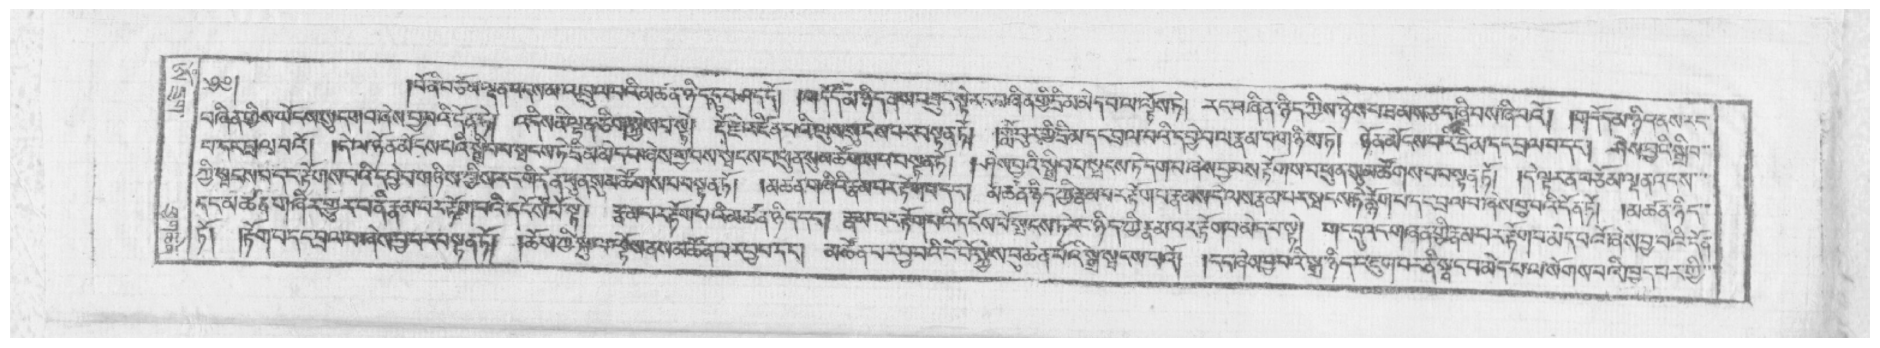

In [20]:
idx = 10
test_image_name = os.path.basename(images[idx]).split(".")[0]
print(test_image_name)
test_image = cv2.imread(images[idx])

show_image(test_image)

In [56]:
prediction, rotated_image, line_images, sorted_contours, bbox, peaks = line_inference.predict(test_image, 0)
line_images = [tweak_image(x) for x in line_images]

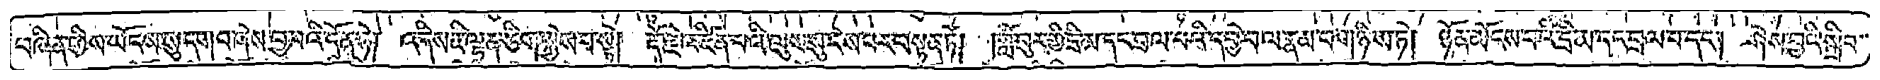

In [57]:
show_image(line_images[1])

In [58]:
np_img_batch = [
            prepare_ocr_image2(
                x, target_width=ocr_inference._input_width, target_height=ocr_inference._input_height
            ) for x in line_images]
np_img_batch = np.array(np_img_batch)
print(np_img_batch.shape)

(6, 1, 80, 2000)


In [59]:
predicted_text, raw = ocr_inference.run(np_img_batch, replace_tsheg=" ")
for line in predicted_text:
    #text = text.replace(" ", "")
    #text = text.replace("§", " ")
    print(line)

za na cas an hyumpag/gn da rmaaudga na myamcmstaga ta/kan tan gnyisnasmas an//rgan da
 m tham cu dag pa nas bhyab nhana nA/nzes rkan s pa d/rnag rgan la rnam sus ngte//rual dza'bya ba la rnam pa rgnyi gaa/na rna mangs par tha ma dang bral ba dang /sham tu msgan 
mpar//rnalan rnamngs pa'i skar bathan as cuns brgyun gun agcccudrtag cab rgun durgamn//n npa
skyan chagcanag can 'd ba gnyis kying 'n shen rnkun du 'rtsgs pa bstan te//mtshan nen 'rnmpa'rtargn/nyn ngas rams rnam par spang rte rnags thams can than na
denmmatagsrgyan parno rnam par thagangzin dsz st/nama'rtag tatan na/rnamnh dbm n rtag camnpa ste/rgang rdunndi gzhan gkyi rnampar rtag cathan a na rgya c
te/rtag pa dang thamsha' rgyu ngan bstan ta//rthag saltsha rnap a smras bu can pani sgra spangs pan//tug nyan 'jugcan snang bamham gaTmacuyi 


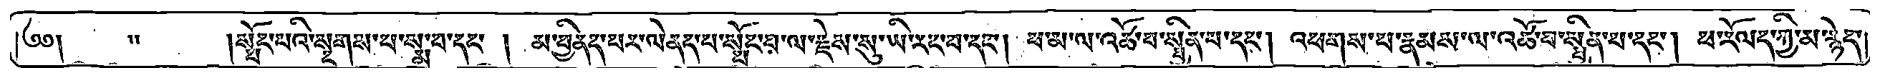

In [10]:
show_image(line_images[0])

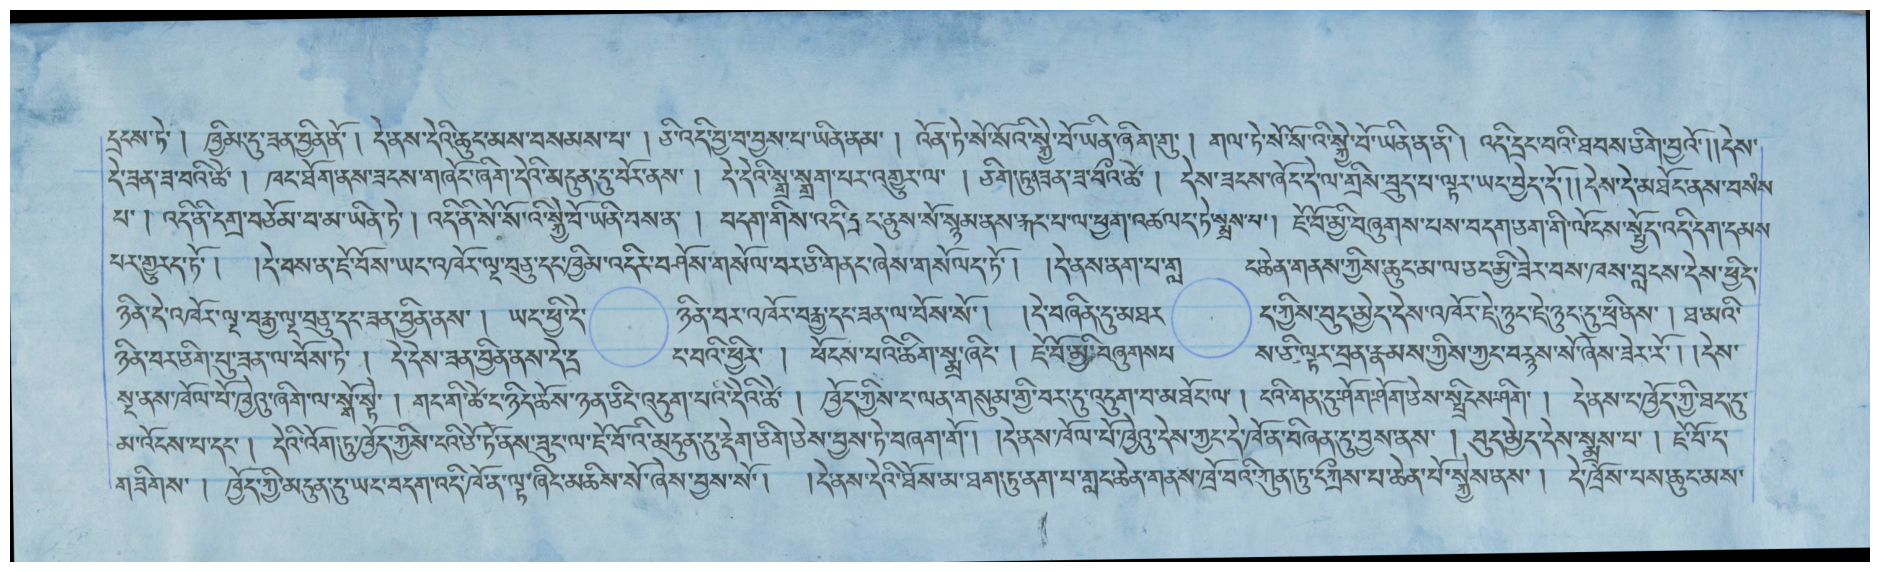

In [21]:
show_image(rotated_image)

In [13]:
from Utils import build_xml_document

converter = pyewts.pyewts()

In [14]:
output_dir = os.path.join(data_root, "predictions_jan2024")
create_dir(output_dir)
xml_out = os.path.join(output_dir,"page")
create_dir(xml_out)

for idx, image_path in tqdm(enumerate(images), total=len(images)):
    image_name = os.path.basename(images[idx]).split(".")[0]
    image = cv2.imread(images[idx])
    prediction, rotated_image, line_images, sorted_contours, bbox, peaks = line_inference.predict(image, 0)


    if len(line_images) > 0:
        line_images = [tweak_image(x) for x in line_images]
        np_img_batch = [
                    prepare_ocr_image2(
                        x, target_width=ocr_inference._input_width, target_height=ocr_inference._input_height
                    ) for x in line_images]
        np_img_batch = np.array(np_img_batch)

        predicted_text, raw = ocr_inference.run(np_img_batch, replace_tsheg=" ")
        predicted_text = [converter.toUnicode(x) for x in predicted_text]

        xml_results = build_xml_document(rotated_image, image_name, bbox, sorted_contours, predicted_text)

        with open(f"{xml_out}/{image_name}.xml", "w", encoding="utf-8") as f:
            f.write(xml_results)

100%|██████████| 612/612 [17:06<00:00,  1.68s/it]
